In [2]:
rows = []
for f in sorted(data.glob("fbil_*.xlsx")):
    d = fbil_date(f)
    name_date = f.stem.replace("fbil_", "")
    rows.append((f.name, name_date, None if d is None else str(d.date())))

check = pd.DataFrame(rows, columns=["file", "name_date", "internal_date"])
check["match"] = check["name_date"] == check["internal_date"]

print(len(check), "files")
print("mismatches:")
print(check[~check["match"]])
print("same internal date twice:")
print(check[check.duplicated("internal_date", keep=False)])

35 files
mismatches:
                    file   name_date internal_date  match
0   fbil_2025-07-25.xlsx  2025-07-25    2025-07-30  False
1   fbil_2025-10-25.xlsx  2025-10-25    2025-10-31  False
2   fbil_2025-11-25.xlsx  2025-11-25    2025-11-28  False
3   fbil_2025-12-25.xlsx  2025-12-25    2025-12-31  False
4   fbil_2025-12-30.xlsx  2025-12-30    2025-12-31  False
23  fbil_2026-09-31.xlsx  2026-09-31    2026-09-04  False
same internal date twice:
                    file   name_date internal_date  match
3   fbil_2025-12-25.xlsx  2025-12-25    2025-12-31  False
4   fbil_2025-12-30.xlsx  2025-12-30    2025-12-31  False
5   fbil_2025-12-31.xlsx  2025-12-31    2025-12-31   True
18  fbil_2026-09-04.xlsx  2026-09-04    2026-09-04   True
23  fbil_2026-09-31.xlsx  2026-09-31    2026-09-04  False


In [3]:
for _, r in check[~check["match"]].iterrows():
    if r["internal_date"] is None:
        print("could not read:", r["file"])
        continue
    old = data / r["file"]
    new = data / f"fbil_{r['internal_date']}.xlsx"
    if new.exists():
        print("CONFLICT, not renaming:", r["file"], "->", new.name)
    else:
        old.rename(new)
        print("renamed", r["file"], "->", new.name)

renamed fbil_2025-07-25.xlsx -> fbil_2025-07-30.xlsx
renamed fbil_2025-10-25.xlsx -> fbil_2025-10-31.xlsx
renamed fbil_2025-11-25.xlsx -> fbil_2025-11-28.xlsx
CONFLICT, not renaming: fbil_2025-12-25.xlsx -> fbil_2025-12-31.xlsx
CONFLICT, not renaming: fbil_2025-12-30.xlsx -> fbil_2025-12-31.xlsx
CONFLICT, not renaming: fbil_2026-09-31.xlsx -> fbil_2026-09-04.xlsx


In [4]:
targets = ["2026-10-05", "2026-10-06", "2026-10-07", "2026-10-08", "2026-10-09",
           "2026-10-12", "2026-10-13", "2026-10-14", "2026-10-15", "2026-10-16",
           "2026-10-01", "2026-09-25", "2026-09-18", "2026-09-11", "2026-09-04",
           "2026-08-28", "2026-08-21", "2026-08-14", "2026-08-07", "2026-07-31"]

have = sorted(p.stem.replace("fbil_", "") for p in data.glob("fbil_*.xlsx"))
print(len(have), "files in data/")
print("missing:", [t for t in targets if t not in have])

35 files in data/
missing: []


In [5]:
import glob
import numpy as np
import pandas as pd

TENORS = [1, 2, 3, 5, 7, 10, 15, 20, 30]


def load_fbil(path):
    raw = pd.read_excel(path, header=None)
    val_date = pd.to_datetime(raw.iloc[2, 2], format="%d-%b-%Y")
    hdr = raw.index[raw[0] == "ISIN"][0]
    df = raw.iloc[hdr + 1:, :8].copy()
    df.columns = ["isin", "coupon", "maturity", "price", "ytm", "remark1", "remark2", "remark3"]
    df = df[df["isin"].astype(str).str.startswith("IN")]
    df["maturity"] = pd.to_datetime(df["maturity"], errors="coerce")
    for col in ["coupon", "price", "ytm"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["maturity", "price", "ytm"])
    df = df[~df["remark1"].isin(["FRB", "IIB"])]
    df["years"] = (df["maturity"] - val_date).dt.days / 365.25
    return val_date, df


def curve_at_tenors(df, tenors=TENORS):
    d = df[df["years"] > 0].sort_values("years")
    out = {}
    for t in tenors:
        if d["years"].min() <= t <= d["years"].max():
            out[t] = float(np.interp(t, d["years"], d["ytm"]))
        else:
            out[t] = np.nan
    return out


def build_table(folder="data"):
    rows = {}
    for f in sorted(glob.glob(f"{folder}/*.xlsx")):
        d, df = load_fbil(f)
        rows[d] = curve_at_tenors(df)
    table = pd.DataFrame(rows).T.sort_index()
    table.index.name = "date"
    return table

In [8]:
from gsec_data import *

table = build_table("data")
table.to_csv("data/curve_table.csv")
print(table.shape)
table.round(3)

(32, 9)


,1,2,3,5,7,10,15,20,30
date,,,,,,,,,
2025-07-30,5.629,5.738,5.896,6.090,6.332,6.509,6.681,6.827,7.050
2025-10-31,5.652,5.739,5.916,6.227,6.542,6.540,6.917,7.076,7.229
2025-11-28,5.605,5.741,5.814,6.252,6.501,6.595,6.945,7.065,7.328
2025-12-31,5.642,5.781,5.888,6.382,6.631,6.706,7.020,7.152,7.314
2026-01-30,5.718,5.856,6.029,6.412,6.683,6.777,7.115,7.243,7.400
2026-02-27,5.578,5.694,5.932,6.292,6.576,6.719,7.107,7.249,7.399
2026-03-30,5.896,6.409,6.433,6.801,7.090,7.111,7.490,7.665,7.703
2026-04-30,5.928,6.243,6.441,6.779,7.001,7.093,7.354,7.479,7.636
2026-05-29,6.128,6.406,6.556,6.884,7.009,7.038,7.388,7.549,7.669


In [7]:
%%writefile gsec_data.py
import glob
import numpy as np
import pandas as pd

TENORS = [1, 2, 3, 5, 7, 10, 15, 20, 30]


def load_fbil(path):
    raw = pd.read_excel(path, header=None)
    val_date = pd.to_datetime(raw.iloc[2, 2], format="%d-%b-%Y")
    hdr = raw.index[raw[0] == "ISIN"][0]
    df = raw.iloc[hdr + 1:, :8].copy()
    df.columns = ["isin", "coupon", "maturity", "price", "ytm", "remark1", "remark2", "remark3"]
    df = df[df["isin"].astype(str).str.startswith("IN")]
    df["maturity"] = pd.to_datetime(df["maturity"], errors="coerce")
    for col in ["coupon", "price", "ytm"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["maturity", "price", "ytm"])
    df = df[~df["remark1"].isin(["FRB", "IIB"])]
    df["years"] = (df["maturity"] - val_date).dt.days / 365.25
    return val_date, df


def curve_at_tenors(df, tenors=TENORS):
    d = df[df["years"] > 0].sort_values("years")
    out = {}
    for t in tenors:
        if d["years"].min() <= t <= d["years"].max():
            out[t] = float(np.interp(t, d["years"], d["ytm"]))
        else:
            out[t] = np.nan
    return out


def build_table(folder="data"):
    rows = {}
    for f in sorted(glob.glob(f"{folder}/*.xlsx")):
        d, df = load_fbil(f)
        rows[d] = curve_at_tenors(df)
    table = pd.DataFrame(rows).T.sort_index()
    table.index.name = "date"
    return table

Writing gsec_data.py


In [9]:
import os
print(os.getcwd())
print([f for f in os.listdir() if f.endswith(".py")])

C:\Users\Bharath\gsec-dashboard
['gsec_data.py']


In [10]:
from gsec_data import *

table = build_table("data")
table.to_csv("data/curve_table.csv")
print(table.shape)
table.round(3)

(32, 9)


,1,2,3,5,7,10,15,20,30
date,,,,,,,,,
2025-07-30,5.629,5.738,5.896,6.090,6.332,6.509,6.681,6.827,7.050
2025-10-31,5.652,5.739,5.916,6.227,6.542,6.540,6.917,7.076,7.229
2025-11-28,5.605,5.741,5.814,6.252,6.501,6.595,6.945,7.065,7.328
2025-12-31,5.642,5.781,5.888,6.382,6.631,6.706,7.020,7.152,7.314
2026-01-30,5.718,5.856,6.029,6.412,6.683,6.777,7.115,7.243,7.400
2026-02-27,5.578,5.694,5.932,6.292,6.576,6.719,7.107,7.249,7.399
2026-03-30,5.896,6.409,6.433,6.801,7.090,7.111,7.490,7.665,7.703
2026-04-30,5.928,6.243,6.441,6.779,7.001,7.093,7.354,7.479,7.636
2026-05-29,6.128,6.406,6.556,6.884,7.009,7.038,7.388,7.549,7.669


In [11]:
from gsec_data import load_fbil
import pandas as pd
from pathlib import Path

rows = []
for f in sorted(Path("data").glob("fbil_*.xlsx")):
    d, _ = load_fbil(f)
    rows.append((f.name, str(d.date())))
chk = pd.DataFrame(rows, columns=["file", "internal_date"])
print(chk[chk.duplicated("internal_date", keep=False)])
print(chk[chk["file"] != "fbil_" + chk["internal_date"] + ".xlsx"])

                    file internal_date
3   fbil_2025-12-25.xlsx    2025-12-31
4   fbil_2025-12-30.xlsx    2025-12-31
5   fbil_2025-12-31.xlsx    2025-12-31
18  fbil_2026-09-04.xlsx    2026-09-04
23  fbil_2026-09-31.xlsx    2026-09-04
                    file internal_date
3   fbil_2025-12-25.xlsx    2025-12-31
4   fbil_2025-12-30.xlsx    2025-12-31
23  fbil_2026-09-31.xlsx    2026-09-04


In [12]:
from gsec_data import load_fbil, curve_at_tenors

pairs = [("fbil_2025-12-25.xlsx", "fbil_2025-12-31.xlsx"),
         ("fbil_2025-12-30.xlsx", "fbil_2025-12-31.xlsx"),
         ("fbil_2026-09-31.xlsx", "fbil_2026-09-04.xlsx")]

for dup, keep in pairs:
    a = curve_at_tenors(load_fbil(f"data/{dup}")[1])
    b = curve_at_tenors(load_fbil(f"data/{keep}")[1])
    same = all(abs(a[t] - b[t]) < 1e-9 for t in a)
    print(dup, "identical to", keep, ":", same)

fbil_2025-12-25.xlsx identical to fbil_2025-12-31.xlsx : True
fbil_2025-12-30.xlsx identical to fbil_2025-12-31.xlsx : True
fbil_2026-09-31.xlsx identical to fbil_2026-09-04.xlsx : True


In [15]:
from importlib import reload
import gsec_data
reload(gsec_data)

table = gsec_data.build_table("data")
table.to_csv("data/curve_table.csv")
print(table.shape)
print(table.isna().sum().sum(), "blanks")
print(table.index.is_monotonic_increasing, table.index.is_unique)

(32, 9)
0 blanks
True True


In [16]:
def show_bracket(date_str, tenor):
    d, b = gsec_data.load_fbil(f"data/fbil_{date_str}.xlsx")
    b = b[b["years"] > 0].sort_values("years")
    lo = b[b["years"] <= tenor].tail(1)[["isin", "years", "ytm"]]
    hi = b[b["years"] >= tenor].head(1)[["isin", "years", "ytm"]]
    print(date_str, tenor, "Y")
    print(lo.to_string(index=False))
    print(hi.to_string(index=False))
    print("table value:", round(table.loc[date_str, tenor], 4))

show_bracket("2026-10-16", 10)
show_bracket("2026-09-09", 5)
show_bracket("2026-08-14", 30)

2026-10-16 10 Y
        isin   years    ytm
IN0020060045 9.64271 7.4176
        isin     years    ytm
IN0020220102 10.176591 7.3953
table value: 7.4027
2026-09-09 5 Y
        isin   years    ytm
IN0020260074 4.99384 6.5591
        isin    years    ytm
IN0020170042 5.021218 6.5594
table value: 6.5592
2026-08-14 30 Y
        isin     years    ytm
IN0020260017 29.702943 7.3069
        isin    years    ytm
IN0020190057 32.84052 7.3958
table value: 7.3153


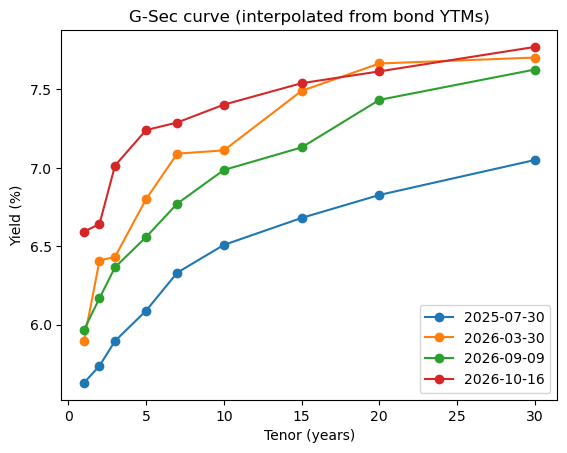

In [17]:
import matplotlib.pyplot as plt

for dt in ["2025-07-30", "2026-03-30", "2026-09-09", "2026-10-16"]:
    plt.plot(table.columns, table.loc[dt], marker="o", label=dt)
plt.xlabel("Tenor (years)")
plt.ylabel("Yield (%)")
plt.title("G-Sec curve (interpolated from bond YTMs)")
plt.legend()
plt.show()

In [18]:
%%writefile gsec_changes.py
import pandas as pd
from pandas.tseries.offsets import BDay


def changes_bps(table, offset, tol_days=0):
    """Yield change in bps versus the date one 'offset' earlier.
    If no row exists within tol_days of that target date, the result is NaN."""
    out = pd.DataFrame(index=table.index, columns=table.columns, dtype=float)
    idx = table.index
    for d in idx:
        target = d - offset
        pos = idx.get_indexer([target], method="nearest")[0]
        base = idx[pos]
        if base < d and abs((base - target).days) <= tol_days:
            out.loc[d] = (table.loc[d] - table.loc[base]) * 100
    return out


def all_changes(table):
    daily = changes_bps(table, BDay(1), 0)
    weekly = changes_bps(table, pd.Timedelta(days=7), 1)
    monthly = changes_bps(table, pd.DateOffset(months=1), 3)
    return daily, weekly, monthly

Writing gsec_changes.py
